# Structure des tables MovieLens 20M et clés manquantes

Ce notebook charge les 6 tables, décrit chaque colonne, compte les clés manquantes entre tables (dans les deux sens), puis dessine le diagramme.

Bibliothèques : pandas et matplotlib uniquement. Adapter `DATA` au dossier des fichiers.

In [1]:
# 1. Chargement des données
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../data/raw/"   # dossier qui contient les fichiers MovieLens (à adapter)

tables = {
    "movies":        pd.read_csv(DATA + "movies.csv"),
    "links":         pd.read_csv(DATA + "links.csv"),
    "ratings":       pd.read_csv(DATA + "ratings.csv"),   # ou pd.read_parquet(DATA + "ratings.parquet")
    "tags":          pd.read_csv(DATA + "tags.csv"),
    "genome-scores": pd.read_csv(DATA + "genome-scores.csv"),
    "genome-tags":   pd.read_csv(DATA + "genome-tags.csv"),
}
for nom, df in tables.items():
    print(f"{nom:14s} {df.shape}")

movies         (27278, 3)
links          (27278, 3)
ratings        (20000263, 4)
tags           (465564, 4)
genome-scores  (11709768, 3)
genome-tags    (1128, 2)


## Description des colonnes

In [2]:
# 2. Description de chaque colonne : valeurs uniques, nuls, et plage de dates pour les timestamps
def decrire_colonne(serie):
    if serie.name == "timestamp":
        dates = pd.to_datetime(serie, unit="s")
        return f"{dates.min():%d/%m/%Y} → {dates.max():%d/%m/%Y}"
    texte = f"{serie.nunique():,} u.".replace(",", " ")
    nuls = serie.isna().sum()
    if nuls > 0:
        texte += f" · {nuls} nuls ({100 * nuls / len(serie):.1f} %)"
    return texte

for nom, df in tables.items():
    print(nom, {col: decrire_colonne(df[col]) for col in df.columns})

movies {'movieId': '27 278 u.', 'title': '27 262 u.', 'genres': '1 342 u.'}
links {'movieId': '27 278 u.', 'imdbId': '27 278 u.', 'tmdbId': '27 008 u. · 252 nuls (0.9 %)'}
ratings {'userId': '138 493 u.', 'movieId': '26 744 u.', 'rating': '10 u.', 'timestamp': '09/01/1995 → 31/03/2015'}
tags {'userId': '7 801 u.', 'movieId': '19 545 u.', 'tag': '38 643 u. · 16 nuls (0.0 %)', 'timestamp': '24/12/2005 → 31/03/2015'}
genome-scores {'movieId': '10 381 u.', 'tagId': '1 128 u.', 'relevance': '4 000 u.'}
genome-tags {'tagId': '1 128 u.', 'tag': '1 128 u.'}


## Clés manquantes entre tables

In [3]:
# 3. Clés manquantes entre deux tables, dans les deux sens
def manquants(table_a, table_b, cle):
    """Nombre et % de clés distinctes de A absentes de B."""
    cles_a = set(tables[table_a][cle].dropna())
    cles_b = set(tables[table_b][cle].dropna())
    n = len(cles_a - cles_b)
    return n, 100 * n / len(cles_a)

# paires de tables qui partagent une clé
liens = [
    ("links", "movies", "movieId"),
    ("movies", "ratings", "movieId"),
    ("movies", "tags", "movieId"),
    ("movies", "genome-scores", "movieId"),
    ("genome-tags", "genome-scores", "tagId"),
    ("ratings", "tags", "userId"),
]

resultats = []
for a, b, cle in liens:
    n_ab, p_ab = manquants(a, b, cle)
    n_ba, p_ba = manquants(b, a, cle)
    resultats.append({"A": a, "B": b, "clé": cle,
                      "dans A pas dans B": n_ab, "% de A": round(p_ab, 1),
                      "dans B pas dans A": n_ba, "% de B": round(p_ba, 1)})
pd.DataFrame(resultats)

,A,B,clé,dans A pas dans B,% de A,dans B pas dans A,% de B
0,links,movies,movieId,0,0.0,0,0.0
1,movies,ratings,movieId,534,2.0,0,0.0
2,movies,tags,movieId,7733,28.3,0,0.0
3,movies,genome-scores,movieId,16897,61.9,0,0.0
4,genome-tags,genome-scores,tagId,0,0.0,0,0.0
5,ratings,tags,userId,130692,94.4,0,0.0


## Diagramme

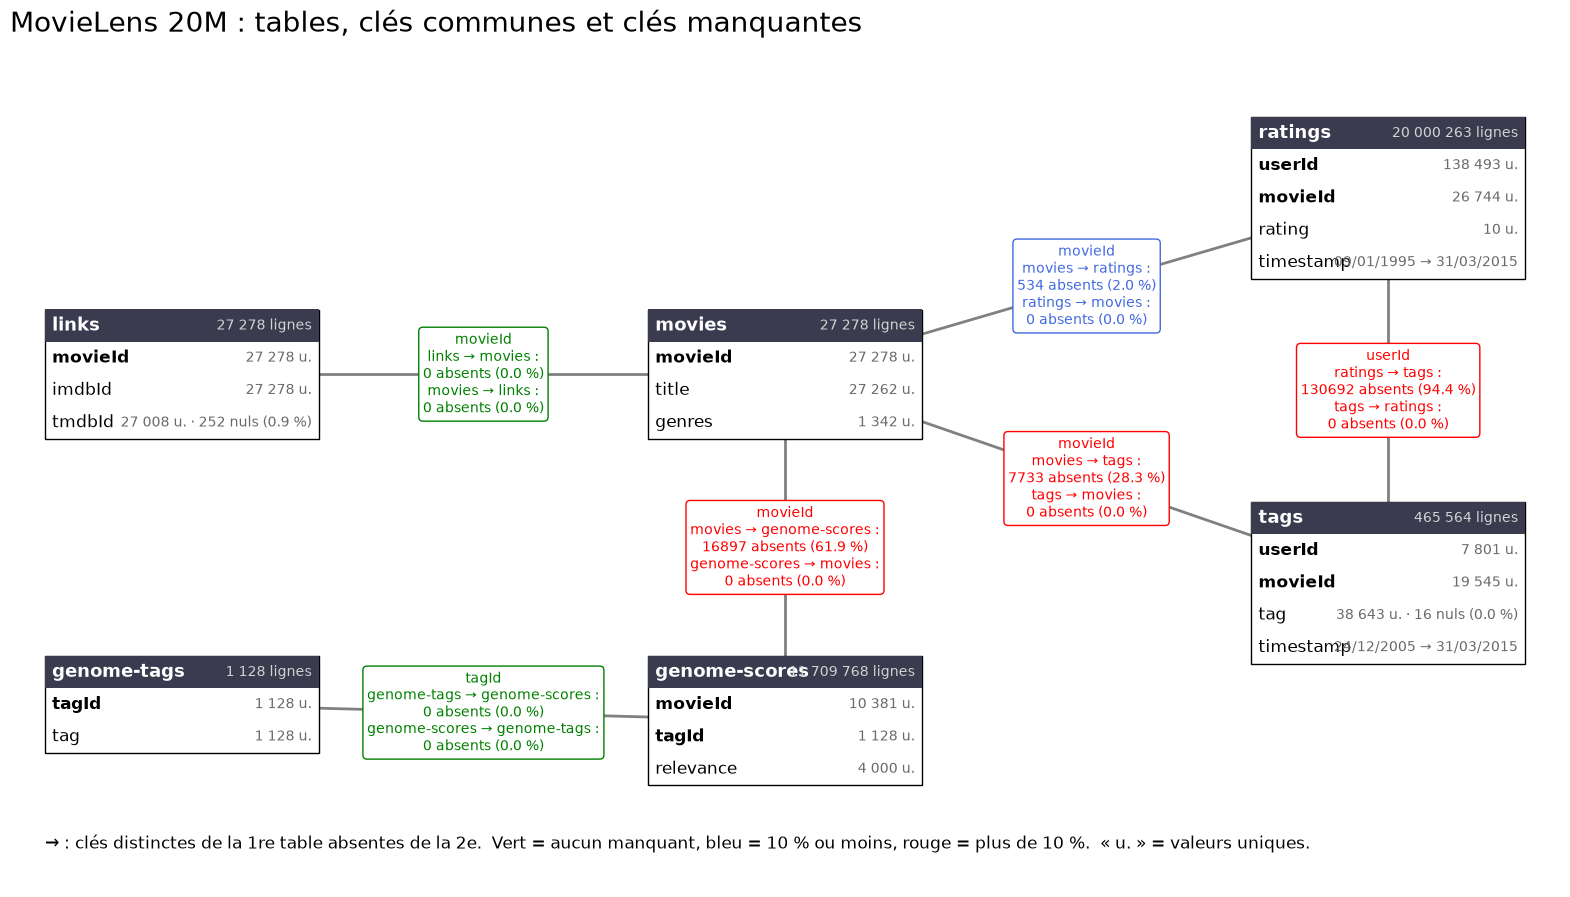

In [4]:
# 4. Diagramme
# position (x, y) du coin haut-gauche de chaque tableau
positions = {
    "links": (0, 7), "movies": (8.6, 7), "ratings": (17.2, 9.5),
    "tags": (17.2, 4.5), "genome-scores": (8.6, 2.5), "genome-tags": (0, 2.5),
}
LARGEUR, HAUTEUR_LIGNE = 3.9, 0.42

def couleur(pourcentage):
    if pourcentage == 0:
        return "green"
    if pourcentage <= 10:
        return "royalblue"
    return "red"

fig, ax = plt.subplots(figsize=(20, 11))
ax.set_xlim(-0.5, 21.6); ax.set_ylim(-0.5, 10.5); ax.axis("off")

# a) les tableaux : un rectangle par table, une ligne par colonne
centres = {}
for nom, (x, y) in positions.items():
    df = tables[nom]
    h = HAUTEUR_LIGNE * (len(df.columns) + 1)
    ax.add_patch(plt.Rectangle((x, y - h), LARGEUR, h, facecolor="white", edgecolor="black", zorder=2))
    ax.add_patch(plt.Rectangle((x, y - HAUTEUR_LIGNE), LARGEUR, HAUTEUR_LIGNE, facecolor="#3b3b4f", zorder=2))
    ax.text(x + 0.1, y - HAUTEUR_LIGNE / 2, nom, color="white", weight="bold", va="center", fontsize=13, zorder=3)
    ax.text(x + LARGEUR - 0.1, y - HAUTEUR_LIGNE / 2, f"{len(df):,} lignes".replace(",", " "),
            color="lightgray", ha="right", va="center", fontsize=10, zorder=3)
    for i, col in enumerate(df.columns):
        yy = y - HAUTEUR_LIGNE * (i + 1.5)
        est_cle = col in ("movieId", "userId", "tagId")
        ax.text(x + 0.1, yy, col, va="center", fontsize=12, weight="bold" if est_cle else "normal", zorder=3)
        ax.text(x + LARGEUR - 0.1, yy, decrire_colonne(df[col]), ha="right", va="center", fontsize=10, color="dimgray", zorder=3)
    centres[nom] = (x + LARGEUR / 2, y - h / 2)

# b) les liens : un trait entre les centres, une étiquette colorée au milieu
for r in resultats:
    (x1, y1), (x2, y2) = centres[r["A"]], centres[r["B"]]
    ax.plot([x1, x2], [y1, y2], color="gray", lw=2, zorder=1)
    texte = (f"{r['clé']}\n"
             f"{r['A']} → {r['B']} :\n{r['dans A pas dans B']} absents ({r['% de A']} %)\n"
             f"{r['B']} → {r['A']} :\n{r['dans B pas dans A']} absents ({r['% de B']} %)")
    c = couleur(max(r["% de A"], r["% de B"]))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, texte, ha="center", va="center", fontsize=10, color=c,
            bbox=dict(facecolor="white", edgecolor=c, boxstyle="round"), zorder=4)

ax.text(0, 0, "→ : clés distinctes de la 1re table absentes de la 2e.  Vert = aucun manquant, bleu = 10 % ou moins, rouge = plus de 10 %.  « u. » = valeurs uniques.", fontsize=12)
ax.set_title("MovieLens 20M : tables, clés communes et clés manquantes", fontsize=20, loc="left")
plt.savefig("diagramme_tables_cles.png", dpi=150, bbox_inches="tight")
plt.show()